# Split Conformal Prediction — Mix Dataset (PoI, 306 features)

**Method**: Inductive (split) conformal prediction with the LAC nonconformity score.  
**Coverage guarantee**: marginal coverage ≥ 1 − α for any exchangeable test point.  
**Stability**: each metric is averaged over 200 random 50/50 calibration/test splits.  
**Models**: best-strategy seed-42 predictions for TabPFN, Extra Trees, LightGBM, XGBoost
(from `Mix_Results_PoI`).

---
### Theory recap

Given n calibration examples and a softmax model:

1. **Nonconformity score** (LAC): $s(x,y) = 1 - \hat{p}(x)_y$  
   i.e. 1 minus the probability the model places on the *true* class.  
   Low score → model is confident and correct. High score → model is wrong or uncertain.

2. **Calibration quantile** at level α:  
   $$\hat{q}_\alpha = \text{Quantile}_{\lceil(n+1)(1-\alpha)\rceil/n}(s_1, \ldots, s_n)$$  
   The extra $(n+1)/n$ factor gives finite-sample coverage ≥ $1-\alpha$.

3. **Prediction set**:  
   $$C_\alpha(x) = \{ k : 1 - \hat{p}(x)_k \leq \hat{q}_\alpha \} = \{ k : \hat{p}(x)_k \geq 1 - \hat{q}_\alpha \}$$

4. **Marginal coverage guarantee**:  
   $$P(y_{\text{true}} \in C_\alpha(x)) \geq 1 - \alpha$$

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Locate project root (directory containing scripts/ and Mix_Results_PoI/)
_cwd = os.getcwd()
ROOT = _cwd
for _c in [_cwd] + [os.path.abspath(os.path.join(_cwd, *['..'] * i)) for i in range(1, 4)]:
    if os.path.isdir(os.path.join(_c, 'scripts')) and os.path.isdir(os.path.join(_c, 'Mix_Results_PoI')):
        ROOT = _c
        break

sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from model_colors import MODEL_COLORS

RESULTS  = 'Mix_Results_PoI'
DATA_DIR = os.path.join(ROOT, RESULTS, 'data')
FIG_DIR  = os.path.join(ROOT, RESULTS, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'sans-serif'})

CLASS_NAMES = ['Allele', 'Back Stutter', 'Forward Stutter', 'Pull-Up']

print('Project root:', ROOT)

Project root: C:\Users\DT User\Documents\GitHub\ML_in_LTDNA


## 1  Load prediction data

In [2]:
MODELS = [
    ('tabpfn',      'TabPFN 3.5 (Class Weights)', 'predictions_tabpfn_classweights_v35.csv'),
    ('extratrees',  'Extra Trees (SMOTE)',          'predictions_extratrees_smote.csv'),
    ('lgbm',        'LightGBM (SMOTE)',             'predictions_lgbm_smote.csv'),
    ('xgboost',     'XGBoost (SMOTE)',              'predictions_xgboost_smote.csv'),
]

PROB_COLS_NAMED   = ['Prob_Allele', 'Prob_Back_Stutter', 'Prob_Forward_Stutter', 'Prob_Pull_Up']
PROB_COLS_INDEXED = ['Prob_0', 'Prob_1', 'Prob_2', 'Prob_3']

model_data = {}
for key, label, fname in MODELS:
    df = pd.read_csv(os.path.join(DATA_DIR, fname))
    # Some models (e.g. XGBoost) write indexed probability columns
    pcols = PROB_COLS_NAMED if PROB_COLS_NAMED[0] in df.columns else PROB_COLS_INDEXED
    model_data[key] = {
        'label':  label,
        'color':  MODEL_COLORS.get(key, '#607d8b'),
        'y_true': df['True_Label'].values.astype(int),
        'probs':  df[pcols].values.astype(float),
    }
    print(f"{label:35s}  n={len(df)}  prob_cols={'named' if pcols == PROB_COLS_NAMED else 'indexed'}  classes={sorted(df['True_Label'].unique())}")

# All models share the same test set (same seed-42 80:20 split)
N = len(next(iter(model_data.values()))['y_true'])
print(f'\nClass distribution (n={N}):')
_y = next(iter(model_data.values()))['y_true']
for i, cn in enumerate(CLASS_NAMES):
    print(f'  {i} {cn}: {((_y == i).sum())}  ({100*(_y==i).mean():.1f}%)')

TabPFN 3.5 (Class Weights)           n=86  prob_cols=named  classes=[0, 1, 2, 3]
Extra Trees (SMOTE)                  n=86  prob_cols=named  classes=[0, 1, 2, 3]
LightGBM (SMOTE)                     n=86  prob_cols=named  classes=[0, 1, 2, 3]
XGBoost (SMOTE)                      n=86  prob_cols=indexed  classes=[0, 1, 2, 3]

Class distribution (n=86):
  0 Allele: 45  (52.3%)
  1 Back Stutter: 18  (20.9%)
  2 Forward Stutter: 7  (8.1%)
  3 Pull-Up: 16  (18.6%)


## 2  Core conformal prediction functions

Three pure-numpy functions — no external libraries.

In [3]:
def lac_scores(probs: np.ndarray, y_true: np.ndarray) -> np.ndarray:
    """LAC nonconformity scores: 1 - p_hat[true_class] for each sample."""
    return 1.0 - probs[np.arange(len(y_true)), y_true]


def calibrate(cal_scores: np.ndarray, alpha: float) -> float:
    """Compute the finite-sample conformal quantile q̂ at level alpha."""
    n = len(cal_scores)
    level = np.ceil((n + 1) * (1 - alpha)) / n
    if level > 1.0:
        return np.inf  # α too small for this calibration set size
    return float(np.quantile(cal_scores, level, method='higher'))


def prediction_sets(probs: np.ndarray, q_hat: float) -> list[list[int]]:
    """Return the prediction set for each test sample given q̂."""
    threshold = 1.0 - q_hat  # equivalent: include class k if prob_k >= threshold
    return [list(np.where(row >= threshold)[0]) for row in probs]


# Quick sanity check
demo_probs  = np.array([[0.7, 0.1, 0.1, 0.1],
                         [0.1, 0.6, 0.2, 0.1]])
demo_y      = np.array([0, 1])
demo_scores = lac_scores(demo_probs, demo_y)
demo_q      = calibrate(demo_scores, alpha=0.10)
demo_sets   = prediction_sets(demo_probs, demo_q)

print('Demo nonconformity scores:', demo_scores)
print(f'Demo q̂ (α=0.10):          {demo_q:.4f}')
print('Demo prediction sets:      ', demo_sets)

Demo nonconformity scores: [0.3 0.4]
Demo q̂ (α=0.10):          inf
Demo prediction sets:       [[0, 1, 2, 3], [0, 1, 2, 3]]


## 3  Single split example (α = 0.10)

To illustrate the method before averaging across random splits.

In [4]:
ALPHA_DEMO = 0.10
CAL_FRAC   = 0.50  # 50 % calibration, 50 % test
DEMO_SEED  = 42

rng = np.random.default_rng(DEMO_SEED)
idx = rng.permutation(N)
n_cal    = int(N * CAL_FRAC)
cal_idx  = idx[:n_cal]
test_idx = idx[n_cal:]

print(f'Split: n_cal={len(cal_idx)}, n_test={len(test_idx)}\n')

rows = []
for key, info in model_data.items():
    y  = info['y_true']
    p  = info['probs']

    cal_s  = lac_scores(p[cal_idx], y[cal_idx])
    q_hat  = calibrate(cal_s, ALPHA_DEMO)
    sets   = prediction_sets(p[test_idx], q_hat)

    covered   = [y[test_idx][i] in s for i, s in enumerate(sets)]
    set_sizes = [len(s) for s in sets]

    rows.append({
        'Model':             info['label'],
        'q̂':                round(q_hat, 4),
        'Threshold (1−q̂)':  round(1 - q_hat, 4),
        'Coverage':          round(np.mean(covered), 4),
        'Avg set size':      round(np.mean(set_sizes), 3),
        'Empty sets':        sum(1 for s in sets if len(s) == 0),
        'Trivial sets (=4)': sum(1 for s in sets if len(s) == 4),
    })

demo_df = pd.DataFrame(rows).set_index('Model')
print(f'Results for single split (α={ALPHA_DEMO}, nominal coverage={1-ALPHA_DEMO:.0%}):')
demo_df

Split: n_cal=43, n_test=43

Results for single split (α=0.1, nominal coverage=90%):


,q̂,Threshold (1−q̂),Coverage,Avg set size,Empty sets,Trivial sets (=4)
Model,,,,,,
TabPFN 3.5 (Class Weights),0.7735,0.2265,0.9070,1.163,0,0
Extra Trees (SMOTE),0.6400,0.3600,0.8140,1.070,0,0
LightGBM (SMOTE),0.5403,0.4597,0.7674,0.953,2,0
XGBoost (SMOTE),0.5668,0.4332,0.7674,0.953,2,0


## 4  Coverage vs. α — averaged over 200 random splits

With only 86 test samples, a single split is noisy. Repeating 200 times
with different random seeds gives stable mean ± std bands.

In [5]:
ALPHAS   = np.round(np.arange(0.01, 0.51, 0.01), 2)
N_SPLITS = 200

# results[key][alpha] → list of (coverage, avg_set_size) over splits
results = {key: {a: [] for a in ALPHAS} for key in model_data}

for split_seed in range(N_SPLITS):
    rng_s   = np.random.default_rng(split_seed)
    idx_s   = rng_s.permutation(N)
    n_cal_s = int(N * CAL_FRAC)
    c_idx   = idx_s[:n_cal_s]
    t_idx   = idx_s[n_cal_s:]

    for key, info in model_data.items():
        y, p      = info['y_true'], info['probs']
        cal_s_arr = lac_scores(p[c_idx], y[c_idx])
        y_test    = y[t_idx]
        p_test    = p[t_idx]

        for alpha in ALPHAS:
            q_hat   = calibrate(cal_s_arr, alpha)
            sets    = prediction_sets(p_test, q_hat)
            covered = np.mean([y_test[i] in s for i, s in enumerate(sets)])
            avg_sz  = np.mean([len(s) for s in sets])
            results[key][alpha].append((covered, avg_sz))

print(f'Done — {N_SPLITS} splits × {len(ALPHAS)} α levels × {len(model_data)} models')

Done — 200 splits × 50 α levels × 4 models


## 5  Coverage vs. α plot

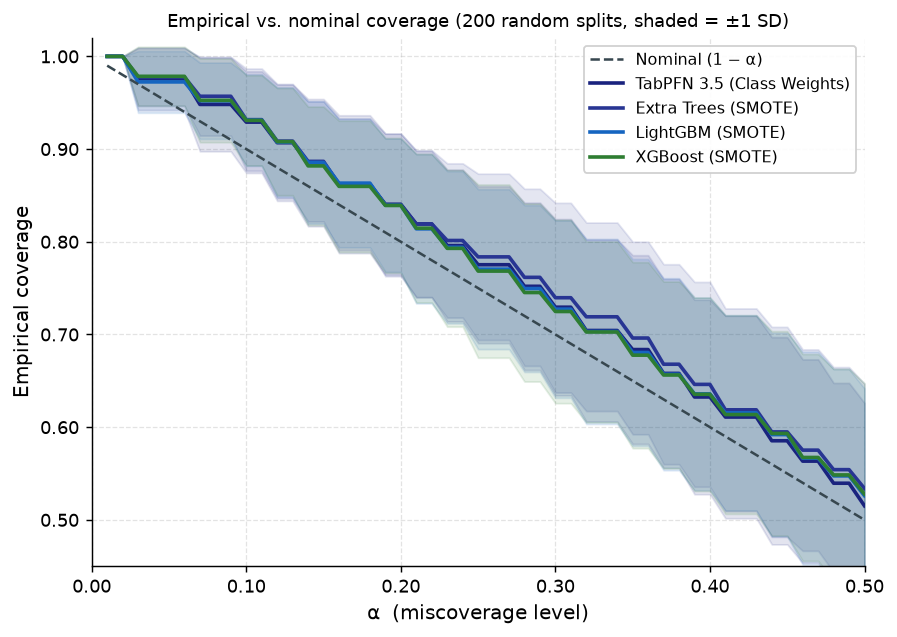

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))

# Diagonal: nominal coverage (1 - α)
ax.plot(ALPHAS, 1 - ALPHAS, color='#37474f', linestyle='--', linewidth=1.4,
        label='Nominal (1 − α)', zorder=5)

for key, info in model_data.items():
    means = np.array([np.mean([r[0] for r in results[key][a]]) for a in ALPHAS])
    stds  = np.array([np.std( [r[0] for r in results[key][a]]) for a in ALPHAS])
    col   = info['color']
    ax.plot(ALPHAS, means, color=col, linewidth=2.0, label=info['label'])
    ax.fill_between(ALPHAS, means - stds, means + stds, color=col, alpha=0.12)

ax.set_xlabel('α  (miscoverage level)', fontsize=11)
ax.set_ylabel('Empirical coverage', fontsize=11)
ax.set_xlim(0, 0.5)
ax.set_ylim(0.45, 1.02)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))
ax.legend(fontsize=9, framealpha=0.9)
ax.grid(linestyle='--', alpha=0.35, linewidth=0.7)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title(f'Empirical vs. nominal coverage ({N_SPLITS} random splits, shaded = ±1 SD)',
             fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'conformal_coverage_vs_alpha.png'), dpi=200, bbox_inches='tight')
plt.show()

## 6  Average prediction set size vs. α

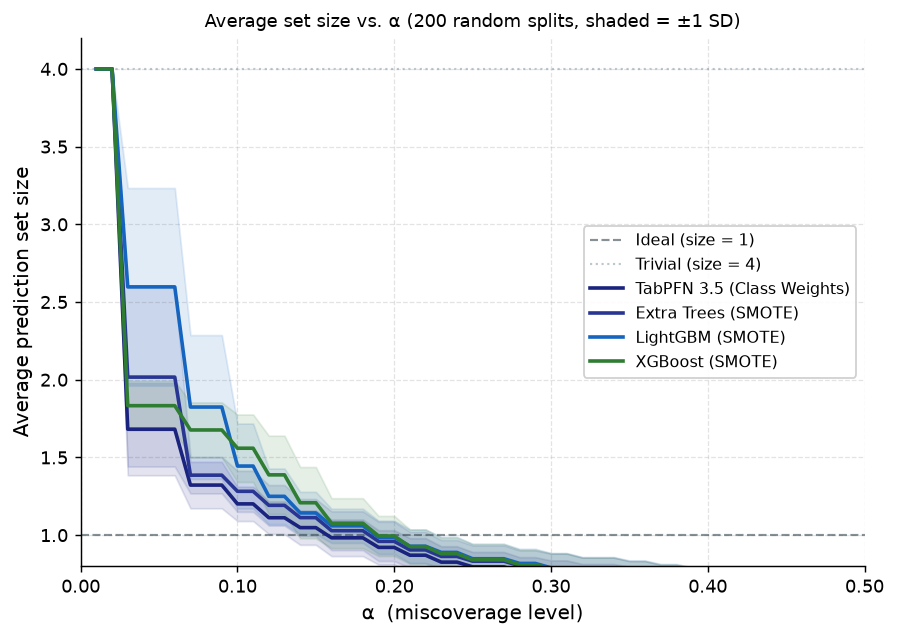

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.axhline(1, color='#37474f', linestyle='--', linewidth=1.2, alpha=0.6,
           label='Ideal (size = 1)')
ax.axhline(len(CLASS_NAMES), color='#90a4ae', linestyle=':', linewidth=1.2, alpha=0.6,
           label='Trivial (size = 4)')

for key, info in model_data.items():
    means = np.array([np.mean([r[1] for r in results[key][a]]) for a in ALPHAS])
    stds  = np.array([np.std( [r[1] for r in results[key][a]]) for a in ALPHAS])
    col   = info['color']
    ax.plot(ALPHAS, means, color=col, linewidth=2.0, label=info['label'])
    ax.fill_between(ALPHAS, means - stds, means + stds, color=col, alpha=0.12)

ax.set_xlabel('α  (miscoverage level)', fontsize=11)
ax.set_ylabel('Average prediction set size', fontsize=11)
ax.set_xlim(0, 0.5)
ax.set_ylim(0.8, 4.2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))
ax.legend(fontsize=9, framealpha=0.9)
ax.grid(linestyle='--', alpha=0.35, linewidth=0.7)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title(f'Average set size vs. α ({N_SPLITS} random splits, shaded = ±1 SD)',
             fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'conformal_setsize_vs_alpha.png'), dpi=200, bbox_inches='tight')
plt.show()

## 7  Conditional (class-conditional) coverage at α = 0.10

Marginal coverage is guaranteed by theory; class-conditional coverage is
not guaranteed but tells you whether under-represented classes get worse sets.

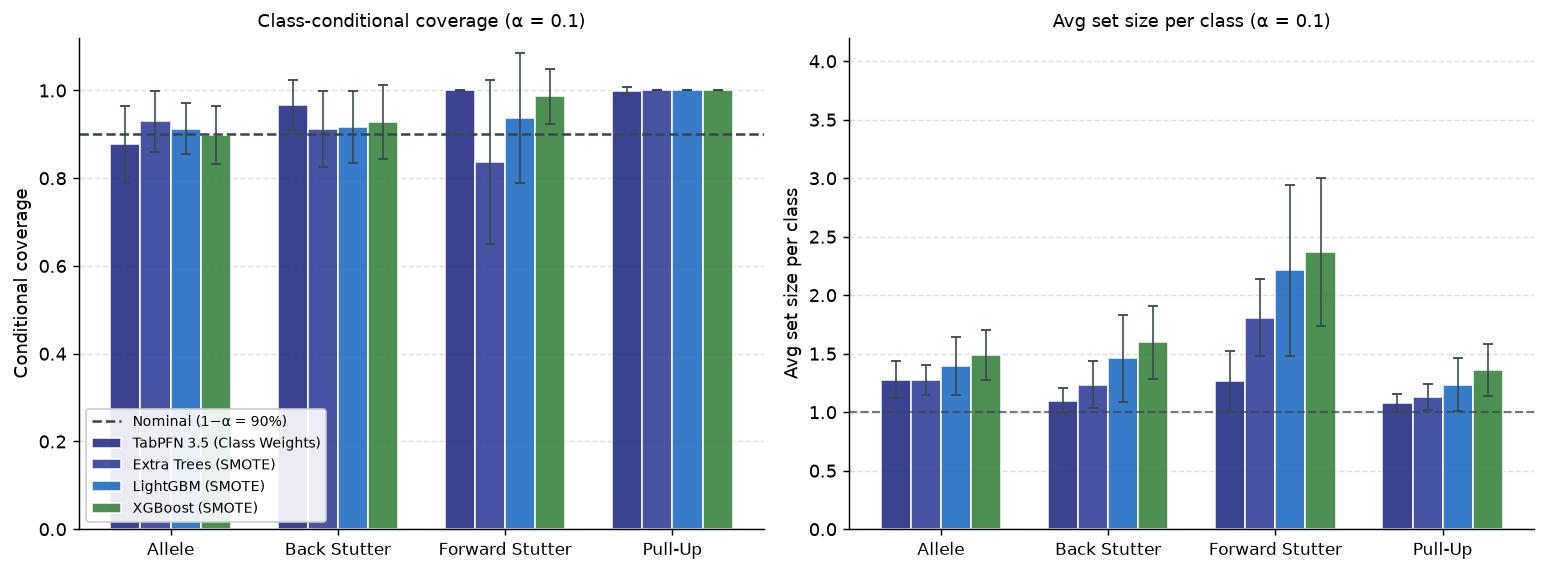

In [8]:
ALPHA_REPORT = 0.10

# For each split, record per-class coverage and set size
cond_results = {key: {cn: [] for cn in CLASS_NAMES} for key in model_data}

for split_seed in range(N_SPLITS):
    rng_s = np.random.default_rng(split_seed)
    idx_s = rng_s.permutation(N)
    c_idx = idx_s[:int(N * CAL_FRAC)]
    t_idx = idx_s[int(N * CAL_FRAC):]

    for key, info in model_data.items():
        y, p   = info['y_true'], info['probs']
        q_hat  = calibrate(lac_scores(p[c_idx], y[c_idx]), ALPHA_REPORT)
        sets   = prediction_sets(p[t_idx], q_hat)
        y_test = y[t_idx]

        for cls_idx, cls_name in enumerate(CLASS_NAMES):
            mask = (y_test == cls_idx)
            if mask.sum() == 0:
                continue
            covered = np.mean([y_test[i] in sets[i] for i in np.where(mask)[0]])
            cond_results[key][cls_name].append(covered)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

x      = np.arange(len(CLASS_NAMES))
width  = 0.18
keys   = list(model_data.keys())
offsets = np.linspace(-(len(keys)-1)*width/2, (len(keys)-1)*width/2, len(keys))

ax = axes[0]
ax.axhline(1 - ALPHA_REPORT, color='#37474f', linestyle='--', linewidth=1.4,
           label=f'Nominal (1−α = {1-ALPHA_REPORT:.0%})')
for i, key in enumerate(keys):
    info = model_data[key]
    means = [np.mean(cond_results[key][cn]) if cond_results[key][cn] else 0
             for cn in CLASS_NAMES]
    stds  = [np.std(cond_results[key][cn])  if cond_results[key][cn] else 0
             for cn in CLASS_NAMES]
    bars = ax.bar(x + offsets[i], means, width=width,
                  color=info['color'], alpha=0.85, edgecolor='white',
                  label=info['label'],
                  yerr=stds, error_kw=dict(ecolor='#37474f', elinewidth=0.9, capsize=3))

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, fontsize=9.5)
ax.set_ylabel('Conditional coverage', fontsize=10)
ax.set_ylim(0, 1.12)
ax.legend(fontsize=8, framealpha=0.9)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title(f'Class-conditional coverage (α = {ALPHA_REPORT})', fontsize=10)

# Per-class set size
cond_sizes = {key: {cn: [] for cn in CLASS_NAMES} for key in model_data}
for split_seed in range(N_SPLITS):
    rng_s = np.random.default_rng(split_seed)
    idx_s = rng_s.permutation(N)
    c_idx = idx_s[:int(N * CAL_FRAC)]
    t_idx = idx_s[int(N * CAL_FRAC):]
    for key, info in model_data.items():
        y, p  = info['y_true'], info['probs']
        q_hat = calibrate(lac_scores(p[c_idx], y[c_idx]), ALPHA_REPORT)
        sets  = prediction_sets(p[t_idx], q_hat)
        y_t   = y[t_idx]
        for cls_idx, cls_name in enumerate(CLASS_NAMES):
            mask = (y_t == cls_idx)
            if mask.sum() > 0:
                avg_s = np.mean([len(sets[i]) for i in np.where(mask)[0]])
                cond_sizes[key][cls_name].append(avg_s)

ax2 = axes[1]
for i, key in enumerate(keys):
    info = model_data[key]
    means = [np.mean(cond_sizes[key][cn]) if cond_sizes[key][cn] else 0
             for cn in CLASS_NAMES]
    stds  = [np.std(cond_sizes[key][cn])  if cond_sizes[key][cn] else 0
             for cn in CLASS_NAMES]
    ax2.bar(x + offsets[i], means, width=width,
            color=info['color'], alpha=0.85, edgecolor='white',
            label=info['label'],
            yerr=stds, error_kw=dict(ecolor='#37474f', elinewidth=0.9, capsize=3))

ax2.axhline(1, color='#37474f', linestyle='--', linewidth=1.2, alpha=0.7,
            label='Ideal (size = 1)')
ax2.set_xticks(x)
ax2.set_xticklabels(CLASS_NAMES, fontsize=9.5)
ax2.set_ylabel('Avg set size per class', fontsize=10)
ax2.set_ylim(0, 4.2)
ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.set_axisbelow(True)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_title(f'Avg set size per class (α = {ALPHA_REPORT})', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'conformal_conditional.png'), dpi=200, bbox_inches='tight')
plt.show()

## 8  Set size distribution at α = 0.10

How often does each model output a singleton, a pair, a triple, or the full set?
Averaged over 200 splits.

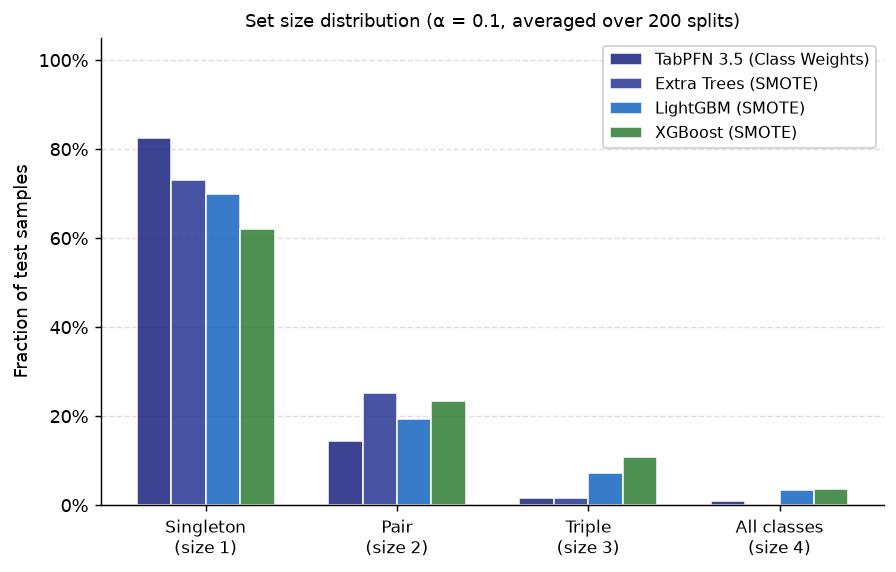

In [9]:
# Collect set-size frequencies averaged over splits
size_freq = {key: np.zeros(5) for key in model_data}  # indices 0..4 (0 = empty)

for split_seed in range(N_SPLITS):
    rng_s = np.random.default_rng(split_seed)
    idx_s = rng_s.permutation(N)
    c_idx = idx_s[:int(N * CAL_FRAC)]
    t_idx = idx_s[int(N * CAL_FRAC):]
    for key, info in model_data.items():
        y, p  = info['y_true'], info['probs']
        q_hat = calibrate(lac_scores(p[c_idx], y[c_idx]), ALPHA_REPORT)
        sets  = prediction_sets(p[t_idx], q_hat)
        for s in sets:
            size_freq[key][len(s)] += 1

# Normalise to fractions
for key in size_freq:
    size_freq[key] /= size_freq[key].sum()

fig, ax = plt.subplots(figsize=(7, 4.5))
bar_w  = 0.18
x_size = np.arange(1, 5)
for i, key in enumerate(keys):
    info = model_data[key]
    fracs = [size_freq[key][s] for s in range(1, 5)]
    bars = ax.bar(x_size + offsets[i], fracs, width=bar_w,
                  color=info['color'], alpha=0.85, edgecolor='white',
                  label=info['label'])

ax.set_xticks(x_size)
ax.set_xticklabels(['Singleton\n(size 1)', 'Pair\n(size 2)', 'Triple\n(size 3)', 'All classes\n(size 4)'],
                   fontsize=9.5)
ax.set_ylabel('Fraction of test samples', fontsize=10)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.legend(fontsize=9, framealpha=0.9)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title(f'Set size distribution (α = {ALPHA_REPORT}, averaged over {N_SPLITS} splits)', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'conformal_setsize_dist.png'), dpi=200, bbox_inches='tight')
plt.show()

## 9  Efficiency: singleton rate across α levels

Singleton rate = fraction of test samples where the model outputs exactly one class.
Higher is better (more decisive). Plotted alongside coverage to show the tradeoff.

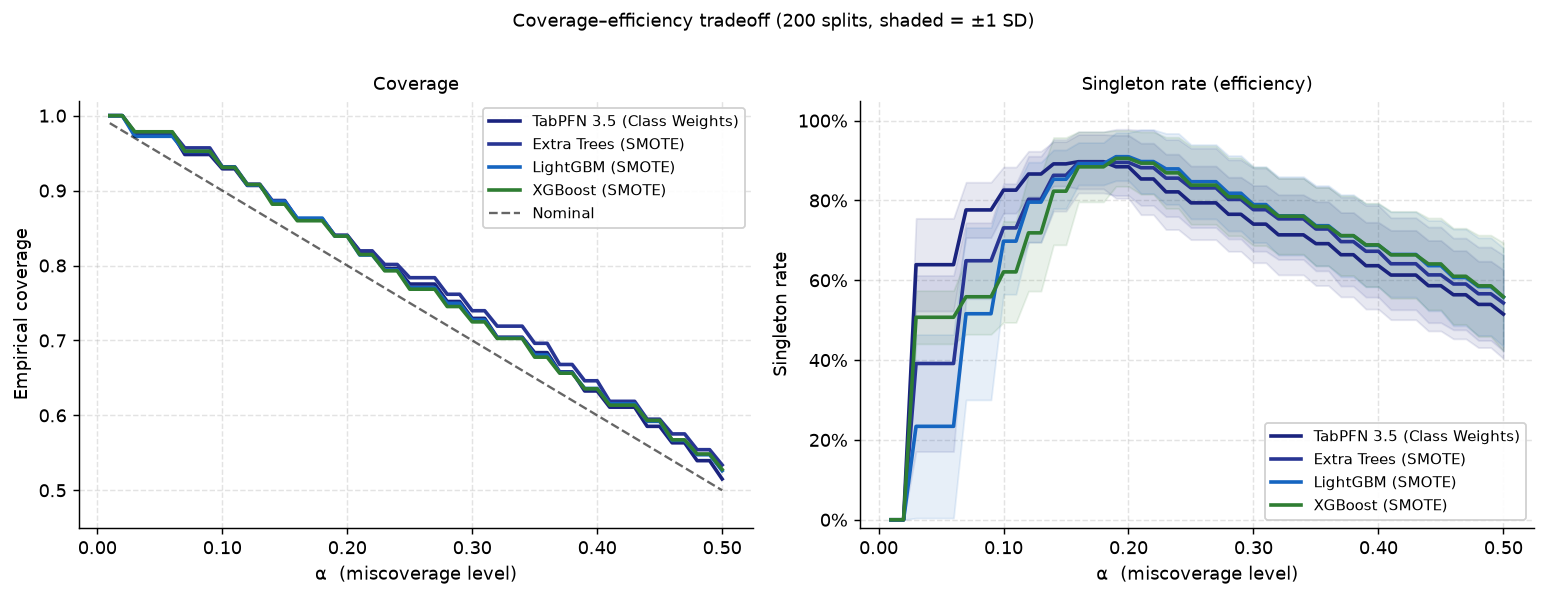

In [10]:
singleton_results = {key: {a: [] for a in ALPHAS} for key in model_data}

for split_seed in range(N_SPLITS):
    rng_s = np.random.default_rng(split_seed)
    idx_s = rng_s.permutation(N)
    c_idx = idx_s[:int(N * CAL_FRAC)]
    t_idx = idx_s[int(N * CAL_FRAC):]
    for key, info in model_data.items():
        y, p      = info['y_true'], info['probs']
        cal_s_arr = lac_scores(p[c_idx], y[c_idx])
        for alpha in ALPHAS:
            q_hat = calibrate(cal_s_arr, alpha)
            sets  = prediction_sets(p[t_idx], q_hat)
            singleton_results[key][alpha].append(np.mean([len(s) == 1 for s in sets]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for key, info in model_data.items():
    col = info['color']

    cov_m = np.array([np.mean([r[0] for r in results[key][a]]) for a in ALPHAS])
    axes[0].plot(ALPHAS, cov_m, color=col, linewidth=2, label=info['label'])

    sin_m = np.array([np.mean(singleton_results[key][a]) for a in ALPHAS])
    sin_s = np.array([np.std(singleton_results[key][a])  for a in ALPHAS])
    axes[1].plot(ALPHAS, sin_m, color=col, linewidth=2, label=info['label'])
    axes[1].fill_between(ALPHAS, sin_m - sin_s, sin_m + sin_s, color=col, alpha=0.10)

axes[0].plot(ALPHAS, 1 - ALPHAS, 'k--', linewidth=1.3, label='Nominal', alpha=0.6)
axes[0].set_ylabel('Empirical coverage', fontsize=10)
axes[0].set_ylim(0.45, 1.02)
axes[0].legend(fontsize=8.5, framealpha=0.9)
axes[0].set_title('Coverage', fontsize=10)

axes[1].set_ylabel('Singleton rate', fontsize=10)
axes[1].set_ylim(-0.02, 1.05)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
axes[1].set_title('Singleton rate (efficiency)', fontsize=10)
axes[1].legend(fontsize=8.5, framealpha=0.9)

for ax in axes:
    ax.set_xlabel('α  (miscoverage level)', fontsize=10)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))
    ax.grid(linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle(f'Coverage–efficiency tradeoff ({N_SPLITS} splits, shaded = ±1 SD)',
             fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'conformal_efficiency.png'), dpi=200, bbox_inches='tight')
plt.show()

## 10  Summary (α = 0.05, 0.10, 0.20)

In [11]:
ALPHA_LEVELS = [0.05, 0.10, 0.20]

rows = []
for alpha in ALPHA_LEVELS:
    for key, info in model_data.items():
        cov_vals = [r[0] for r in results[key][alpha]]
        sz_vals  = [r[1] for r in results[key][alpha]]
        sin_vals = singleton_results[key][alpha]

        rows.append({
            'α':              alpha,
            'Nominal cov.':   f'{1-alpha:.0%}',
            'Model':          info['label'],
            'Empirical cov.': f"{np.mean(cov_vals):.3f} ± {np.std(cov_vals):.3f}",
            'Avg set size':   f"{np.mean(sz_vals):.2f} ± {np.std(sz_vals):.2f}",
            'Singleton rate': f"{np.mean(sin_vals):.1%}",
        })

summary = pd.DataFrame(rows)
print('Summary across α levels (mean ± SD over 200 random splits):')
summary.set_index(['α', 'Nominal cov.', 'Model'])

Summary across α levels (mean ± SD over 200 random splits):


Empirical cov. Avg set size  \
α    Nominal cov. Model                                                    
0.05 95%          TabPFN 3.5 (Class Weights)  0.976 ± 0.034  1.68 ± 0.30   
                  Extra Trees (SMOTE)         0.978 ± 0.031  2.02 ± 0.58   
                  LightGBM (SMOTE)            0.972 ± 0.033  2.60 ± 0.64   
                  XGBoost (SMOTE)             0.978 ± 0.032  1.83 ± 0.16   
0.10 90%          TabPFN 3.5 (Class Weights)  0.929 ± 0.055  1.20 ± 0.11   
                  Extra Trees (SMOTE)         0.932 ± 0.055  1.28 ± 0.13   
                  LightGBM (SMOTE)            0.931 ± 0.049  1.44 ± 0.27   
                  XGBoost (SMOTE)             0.931 ± 0.049  1.56 ± 0.22   
0.20 80%          TabPFN 3.5 (Class Weights)  0.840 ± 0.076  0.92 ± 0.11   
                  Extra Trees (SMOTE)         0.840 ± 0.077  0.96 ± 0.13   
                  LightGBM (SMOTE)            0.839 ± 0.072  0.99 ± 0.11   
                  XGBoost (SMOTE)             0.839 ± 0.073  0.99 ± 0.13   

                                             Singleton rate  
α    Nominal cov. Model                                      
0.05 95%          TabPFN 3.5 (Class Weights)          63.9%  
                  Extra Trees (SMOTE)                 39.2%  
                  LightGBM (SMOTE)                    23.4%  
                  XGBoost (SMOTE)                     50.7%  
0.10 90%          TabPFN 3.5 (Class Weights)          82.6%  
                  Extra Trees (SMOTE)                 73.1%  
                  LightGBM (SMOTE)                    69.8%  
                  XGBoost (SMOTE)                     62.1%  
0.20 80%          TabPFN 3.5 (Class Weights)          88.4%  
                  Extra Trees (SMOTE)                 89.5%  
                  LightGBM (SMOTE)                    91.0%  
                  XGBoost (SMOTE)                     90.5%